In [6]:
import pandas as pd
import kagglehub
from kagglehub import KaggleDatasetAdapter

df = kagglehub.dataset_load(
    KaggleDatasetAdapter.PANDAS,
    "uciml/student-alcohol-consumption",
    "student-mat.csv"
)



In [12]:
with pd.option_context(
    "display.max_columns", None
):
    display(df)

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,3,yes,no,yes,no,yes,yes,yes,no,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,yes,yes,yes,yes,yes,yes,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,yes,no,yes,yes,no,no,4,3,2,1,2,5,4,6,10,10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
390,MS,M,20,U,LE3,A,2,2,services,services,course,other,1,2,2,no,yes,yes,no,yes,yes,no,no,5,5,4,4,5,4,11,9,9,9
391,MS,M,17,U,LE3,T,3,1,services,services,course,mother,2,1,0,no,no,no,no,no,yes,yes,no,2,4,5,3,4,2,3,14,16,16
392,MS,M,21,R,GT3,T,1,1,other,other,course,other,1,1,3,no,no,no,no,no,yes,no,no,5,5,3,3,3,3,3,10,8,7
393,MS,M,18,R,LE3,T,3,2,services,other,course,mother,3,1,0,no,no,no,no,no,yes,yes,no,4,4,1,3,4,5,0,11,12,10


In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      395 non-null    str  
 1   sex         395 non-null    str  
 2   age         395 non-null    int64
 3   address     395 non-null    str  
 4   famsize     395 non-null    str  
 5   Pstatus     395 non-null    str  
 6   Medu        395 non-null    int64
 7   Fedu        395 non-null    int64
 8   Mjob        395 non-null    str  
 9   Fjob        395 non-null    str  
 10  reason      395 non-null    str  
 11  guardian    395 non-null    str  
 12  traveltime  395 non-null    int64
 13  studytime   395 non-null    int64
 14  failures    395 non-null    int64
 15  schoolsup   395 non-null    str  
 16  famsup      395 non-null    str  
 17  paid        395 non-null    str  
 18  activities  395 non-null    str  
 19  nursery     395 non-null    str  
 20  higher      395 non-null    str  
 21  inte

In [44]:
y = df['Dalc']
X = df.loc[:,['age','sex','failures','goout','guardian']]
X

,age,sex,failures,goout,guardian
0,18,F,0,4,mother
1,17,F,0,3,father
2,15,F,3,2,mother
3,15,F,0,2,mother
4,16,F,0,2,father
...,...,...,...,...,...
390,20,M,2,4,other
391,17,M,0,5,mother
392,21,M,3,3,other
393,18,M,0,1,mother


In [49]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import make_column_transformer
from sklearn.pipeline import make_pipeline

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Model
model = RandomForestClassifier(
    n_estimators=150,
    max_depth=10,
    min_samples_split=5,
    min_samples_leaf=3,
    max_features="sqrt",
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

# Preprocessing
column_trans = make_column_transformer(
    (OneHotEncoder(), ["sex","guardian"]),
    remainder="passthrough"
)

# Pipeline
pipe = make_pipeline(column_trans, model)

# Cross-validation on training data
scores = cross_val_score(
    pipe,
    X_train,
    y_train,
    cv=5,
    scoring="accuracy"
)

print("CV scores:", scores)
print("Mean CV accuracy:", scores.mean())

# Train final model
pipe

CV scores: [0.53125    0.47619048 0.50793651 0.55555556 0.44444444]
Mean CV accuracy: 0.5030753968253968


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columntransformer', ...), ('randomforestclassifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('onehotencoder', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold:

In [50]:
from sklearn.model_selection import GridSearchCV

# Parameters to test
param_grid = {
    "randomforestclassifier__n_estimators": [100, 150, 300],
    "randomforestclassifier__max_depth": [5, 10, 15, None],
    "randomforestclassifier__min_samples_split": [2, 5, 10],
    "randomforestclassifier__min_samples_leaf": [1, 3, 5],
    "randomforestclassifier__class_weight": [None, "balanced_subsample"]
}

# Grid search
grid = GridSearchCV(
    estimator=pipe,
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
    verbose=1
)

# Train and find best parameters
grid.fit(X_train, y_train)

# Results
print("Best parameters:", grid.best_params_)
print("Best CV accuracy:", grid.best_score_)

Fitting 5 folds for each of 216 candidates, totalling 1080 fits
Best parameters: {'randomforestclassifier__class_weight': None, 'randomforestclassifier__max_depth': 5, 'randomforestclassifier__min_samples_leaf': 3, 'randomforestclassifier__min_samples_split': 10, 'randomforestclassifier__n_estimators': 100}
Best CV accuracy: 0.7025793650793652


In [51]:
from sklearn.metrics import classification_report, confusion_matrix

# Best model is automatically refitted on all training data
best_model = grid.best_estimator_

print("Train accuracy:", best_model.score(X_train, y_train))
print("Test accuracy:", best_model.score(X_test, y_test))

# Predictions
y_pred = best_model.predict(X_test)

print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

Train accuracy: 0.7215189873417721
Test accuracy: 0.6962025316455697
              precision    recall  f1-score   support

           1       0.70      1.00      0.82        55
           2       0.00      0.00      0.00        15
           3       0.00      0.00      0.00         5
           4       0.00      0.00      0.00         2
           5       0.00      0.00      0.00         2

    accuracy                           0.70        79
   macro avg       0.14      0.20      0.16        79
weighted avg       0.48      0.70      0.57        79

[[55  0  0  0  0]
 [15  0  0  0  0]
 [ 5  0  0  0  0]
 [ 2  0  0  0  0]
 [ 2  0  0  0  0]]


/Users/yisraelwasserman/Projects/dsc400-yis0/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/yisraelwasserman/Projects/dsc400-yis0/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/yisraelwasserman/Projects/dsc400-yis0/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this beha

In [52]:
import pandas as pd

results = pd.DataFrame(grid.cv_results_)

display(
    results[[
        "param_randomforestclassifier__max_depth",
        "param_randomforestclassifier__min_samples_leaf",
        "param_randomforestclassifier__n_estimators",
        "mean_test_score",
        "std_test_score"
    ]]
    .sort_values("mean_test_score", ascending=False)
    .head(10)
)

,param_randomforestclassifier__max_depth,param_randomforestclassifier__min_samples_leaf,param_randomforestclassifier__n_estimators,mean_test_score,std_test_score
15,5,3,100,0.702579,0.017573
9,5,3,100,0.699405,0.019380
12,5,3,100,0.699405,0.019380
16,5,3,150,0.699405,0.019380
25,5,5,150,0.699405,0.019380
22,5,5,150,0.699405,0.019380
19,5,5,150,0.699405,0.019380
3,5,1,100,0.699355,0.017490
80,15,5,300,0.696230,0.024975
79,15,5,150,0.696230,0.024975


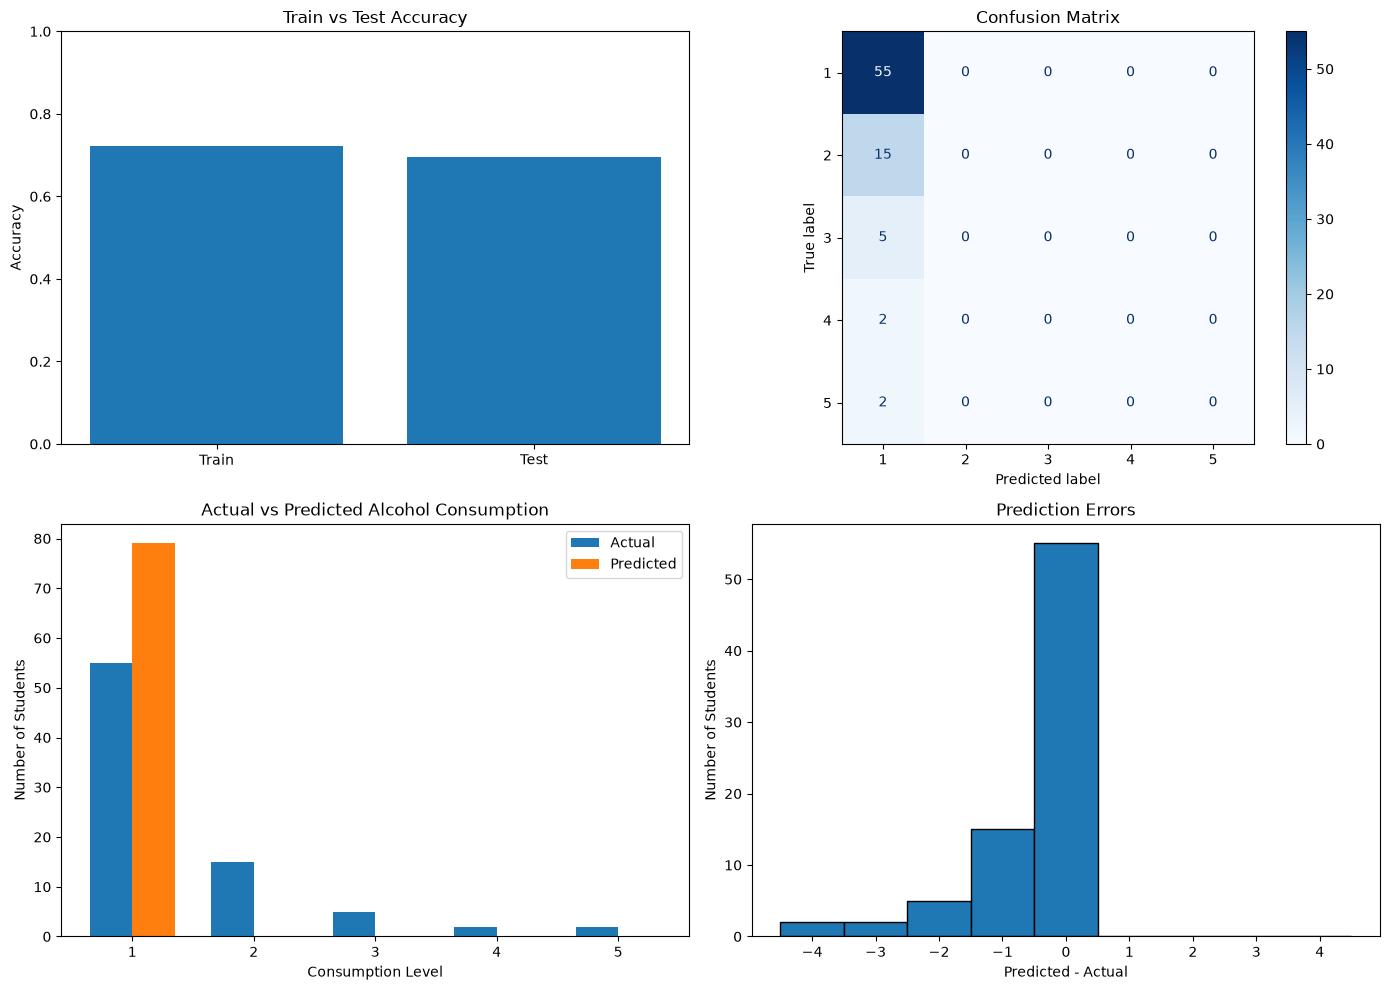

Train Accuracy: 0.722
Test Accuracy: 0.696
Test MAE: 0.494


In [53]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    mean_absolute_error
)

# Best model from GridSearchCV
best_model = grid.best_estimator_

# Predictions
y_train_pred = best_model.predict(X_train)
y_test_pred = best_model.predict(X_test)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Train vs Test Accuracy
train_acc = accuracy_score(y_train, y_train_pred)
test_acc = accuracy_score(y_test, y_test_pred)

axes[0, 0].bar(
    ["Train", "Test"],
    [train_acc, test_acc]
)
axes[0, 0].set_title("Train vs Test Accuracy")
axes[0, 0].set_ylabel("Accuracy")
axes[0, 0].set_ylim(0, 1)

# 2. Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test, y_test_pred,
    labels=[1, 2, 3, 4, 5],
    ax=axes[0, 1],
    cmap="Blues"
)
axes[0, 1].set_title("Confusion Matrix")

# 3. Actual vs Predicted Distribution
actual = pd.Series(y_test).value_counts().reindex(range(1, 6), fill_value=0)
predicted = pd.Series(y_test_pred).value_counts().reindex(range(1, 6), fill_value=0)

x = np.arange(1, 6)
width = 0.35

axes[1, 0].bar(x - width/2, actual.values, width, label="Actual")
axes[1, 0].bar(x + width/2, predicted.values, width, label="Predicted")
axes[1, 0].set_title("Actual vs Predicted Alcohol Consumption")
axes[1, 0].set_xlabel("Consumption Level")
axes[1, 0].set_ylabel("Number of Students")
axes[1, 0].set_xticks(x)
axes[1, 0].legend()

# 4. Prediction Errors
errors = np.asarray(y_test_pred) - np.asarray(y_test)

axes[1, 1].hist(
    errors,
    bins=np.arange(-4.5, 5.5, 1),
    edgecolor="black"
)
axes[1, 1].set_title("Prediction Errors")
axes[1, 1].set_xlabel("Predicted - Actual")
axes[1, 1].set_ylabel("Number of Students")
axes[1, 1].set_xticks(range(-4, 5))

plt.tight_layout()
plt.show()

print("Train Accuracy:", round(train_acc, 3))
print("Test Accuracy:", round(test_acc, 3))
print("Test MAE:", round(mean_absolute_error(y_test, y_test_pred), 3))